In [9]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Tue Jun  7 12:02:15 2022

@author: sunms498
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from os import walk
import pickle
from pathlib import Path
from shapely.geometry import Point
import geopandas as gpd
from geopandas import GeoDataFrame

import numpy as np

import matplotlib.pyplot as plt
import xarray as xr
from matplotlib.colors import LogNorm
import numpy as np

"""
# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()
"""
from pathlib import Path
from matplotlib.colors import LogNorm
################################################################################
#"""
#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_TOC_noconstraint_supervised_men_CS_constraint05.npy"
filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_CS_constraint07.npy"
prediction_dist_CS = np.load(filename)
prediction_dist_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/prediction_map_dist_DO.npy")




uncertainty_map_CS = np.var(prediction_dist_CS, axis = 0)
prediction_map_CS = np.mean(prediction_dist_CS, axis = 0)

uncertainty_map_DO = np.var(prediction_dist_DO, axis = 0)
prediction_map_DO = np.mean(prediction_dist_DO, axis = 0)

uncertainty_map_CS = np.rot90(np.rot90(np.fliplr(uncertainty_map_CS)))
prediction_map_CS = np.rot90(np.rot90(np.fliplr(prediction_map_CS)))


uncertainty_map_DO = np.rot90(np.rot90(np.fliplr(uncertainty_map_DO)))
prediction_map_DO = np.rot90(np.rot90(np.fliplr(prediction_map_DO)))


#filename = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_CS_constraint05.npy"
#uncertainty_map_CS = np.load(filename)
#uncertainty_map_DO = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/output/predictionmaps_TOC/uncertainty_map_TOC_noconstraint_supervised_men_DO.npy")



dataset_mask = np.load("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/masks/mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

# Create a copy of pm_CS
pm_overlapped = np.copy(prediction_map_DO)

# Mask the values from pm_CS where mask contains NaN values
pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]

# Create a copy of pm_CS
um_overlapped = np.copy(uncertainty_map_DO)

# Mask the values from pm_CS where mask contains NaN values
um_overlapped[np.isnan(dataset_mask)] = uncertainty_map_CS[np.isnan(dataset_mask)]


#prediction_dist_overlapped_chunk= np.copy(prediction_dist_DO)
#pm_overlapped[np.isnan(dataset_mask)] = prediction_map_CS[np.isnan(dataset_mask)]



"""
pm_overlapped = np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/predictionmap_parametersharing/prediction_map_parametersharing_sedrate_soft_lambda_06.npy")
"""
import matplotlib.pyplot as plt
import matplotlib.colors as colors

#plt.figure(figsize=[25, 15], dpi=200)

# Create a lognorm instance
#lognorm = colors.LogNorm(vmin=0.01, vmax=800)

# Plot the overlapped array with lognorm
#plt.imshow(pm_overlapped, norm = lognorm,  cmap="turbo")
#cbar = plt.colorbar()
##################################################################################

# Add colorbar
#cbar = plt.colorbar()

#plt.show()

ds=2.6

file_porosity = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/interim/porosity/grl53425-sup-0002-supinfo.grd"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_porosity = xr.open_dataset(Path(file_porosity), format = 'NETCDF4')
                                                                   
dataset_porosity = rootgrp_porosity.variables['z']

dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))
"""

file_2020 = "/home/sunms498/Data/paper2020/GPSM_Restreppo/prediction.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2020 = xr.open_dataset(Path(file_2020), format = 'NETCDF4')


file_2021 = "/home/sunms498/Data/paper2021/GPSM_Restreppo/Log10_prediction_5m.nc"
#file_porosity = "file_porosity = "/home/sunms498/Data/paper_porosity/GPSM_Restreppo/prediction.nc""
rootgrp_2021 = xr.open_dataset(Path(file_2021), format = 'NETCDF4')


latitudes = rootgrp_porosity.variables['y'] # in theory all the same
longitudes = rootgrp_porosity.variables['x']

latitudes2020 = rootgrp_2020.variables['lat'] # in theory all the same
longitudes2020 = rootgrp_2020.variables['lon']

latitudes2021 = rootgrp_2021.variables['lat'] # in theory all the same
longitudes2021 = rootgrp_2021.variables['lon']

dataset_porosity = rootgrp_porosity.variables['z']
dataset_2020 = rootgrp_2020.variables['z']
dataset_2021 = rootgrp_2021.variables['z']


# #plt.figure(figsize=([20,10]), dpi=300);plt.imshow(np.rot90(np.rot90(np.fliplr(dataset_numpy))))
dataset_numpy_porosity = dataset_porosity.to_numpy()
dataset_numpy_porosity = np.rot90(np.rot90(np.fliplr(dataset_numpy_porosity)))

dataset_numpy_2020 = dataset_2020.to_numpy()
dataset_numpy_2020 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2020)))

dataset_numpy_2021 = dataset_2021.to_numpy()
dataset_numpy_2021 = np.rot90(np.rot90(np.fliplr(dataset_numpy_2021)))

dataset2020mar = (1-dataset_numpy_porosity/100)*ds*(10**dataset_numpy_2020)##


def find_nearest(value,vector):
    vector = np.float64(vector)-np.float64(value);
    return np.argmin(np.abs(vector))


# data_path = Path(Path().resolve().parents[2] / "Data" / "RestrepoKNNsSed") 
# sed_labels_file = "sediments_all_updated.xlsx"

# df = pd.read_excel(Path(data_path / sed_labels_file))

# df = df[["Latitude","Longitude","Sedimentation rate [cm/ka]"]]
# df = df[df["Longitude"]>-180]
# df = df.dropna(how="any")
# df = df[df["Sedimentation rate [cm/ka]"]<200]

# world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
# geometry = [Point(xy) for xy in zip(df['Longitude'], df['Latitude'])]
# gdf = GeoDataFrame(df, geometry=geometry)  
# fig, ax=plt.subplots(figsize=(20,10), dpi=300)
# gdf.plot(ax = world.plot(ax=ax), column = df["Sedimentation rate [cm/ka]"], vmin = 0, vmax = 200,legend = True, legend_kwds={"label":"{Sedimentation rate [cm/ka]}"});
# fig.tight_layout(pad=0)
# ax.set_xlim(-180,180)
# ax.set_ylim(-90,90)
# fig.savefig("/home/sunms498/work/Img/sedimentation_labels.png", bbox_inches='tight', pad_inches=0)
# df.describe()

"""
#feature_image_path ="../../../Data/LeeKNNsTOC/RestrepoFeatureMaps/"
restrepo_features_path = "/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc"
#restrepo_features_path_flipped = Path("/media/sunms498/EXTERNAL_USB/Features_Phrampus_flipped")
restrepo_files = []

for (dirpath, dirnames, filenames) in walk(restrepo_features_path):
    restrepo_files.extend(filenames)

restrepo_files.sort()
len(restrepo_files)

rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')
latitudes = rootgrp.variables['lat']
longitudes = rootgrp.variables['lon']

# restrepo_features = np.empty([len(df),len(restrepo_files[0:len(restrepo_files)])])
# restrepo_features[:] = np.nan
# restrepo_X_mean = np.empty(0)
# restrepo_X_std = np.empty(0)

file_idx = -1
corrupted_files = 0


 
rootgrp = xr.open_dataset(restrepo_features_path, format = 'NETCDF4')


    
#     latitudes = rootgrp.variables['lats'] # in theory all the same
#     longitudes = rootgrp.variables['lons']

dataset = rootgrp.variables['data']
area = 9.297**2 * np.cos(dataset/180 * np.pi)




land_file = Path("/gxfs_work/cau/sunms498/work/nn4sedratetoc/data/raw/island_map.npy")
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1


pm_overlapped[land_map] = 0
um_overlapped[land_map] = 0
"""
# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")
# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))
# prediction_map_flipped[land_map]=np.nan

# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")
prediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")
#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))
prediction_map_flipped_nonan = prediction_map_nonan
prediction_map_flipped_nonan[land_map]=np.nan

mar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)
# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)

# plt.figure(figsize=([20,10]),dpi=300)
# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")
# plt.title("Mass accumulation rate prediction from neural network model(ds=2.6)")#(ours)(converted with MAR=(1-p)(ds)(w); ds $= 2.6$, w: sedimentation rate and p: porosity)
# plt.axis("off")
# plt.colorbar(label='Mass accumulation rate[$g/cm^2/yr$] ')
# #plt.savefig( "/home/sunms498/Data/MassAccumulationRateNaveen"+".png")
# #plt.clim(0, 30)
# #wihtout log

"""

'\n# prediction_map = np.load("prediction_map(withoutlog)RestrepoFeats__AllVS0.2.npy")\n# prediction_map_flipped= np.rot90(np.rot90(np.fliplr(prediction_map)))\n# prediction_map_flipped[land_map]=np.nan\n\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n#prediction_map_nonan= np.load("Sed_regresion_083_RestrepoFeats_AllVS0.2_noNaN.npy")\nprediction_map_nonan= pm_overlapped#np.load("/home/sunms498/work/toc-neural-nets/SelectFeaturesRun/notebooks/SedRate_Naveen/pm_overlap.npy")\n#prediction_map_flipped_nonan= np.rot90(np.rot90(np.fliplr(prediction_map_nonan)))\nprediction_map_flipped_nonan = prediction_map_nonan\nprediction_map_flipped_nonan[land_map]=np.nan\n\nmar_naveen_nonan = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped_nonan/1e3)\n# mar_naveen = (1-(dataset_numpy_porosity/100))*ds*(prediction_map_flipped/1e3)\n\n# plt.figure(figsize=([20,10]),dpi=300)\n# plt.imshow(mar_naveen,norm=LogNorm(vmin=1e-5, vmax=5),cmap="turbo")\n# plt.title

In [10]:

# Flip along the last axis (axis=2)
prediction_dist_DO = np.flip(prediction_dist_DO, axis=2)
prediction_dist_CS = np.flip(prediction_dist_CS, axis=2)

# If you also want to rotate the flipped array, you can use np.rot90
prediction_dist_DO = np.rot90(prediction_dist_DO, k=2, axes=(1, 2))
prediction_dist_CS = np.rot90(prediction_dist_CS, k=2, axes=(1, 2))



prediction_dist_overlapped = np.copy(prediction_dist_DO)

for i in range(prediction_dist_CS.shape[0]):
    # Mask the values from pm_CS where mask contains NaN values
    prediction_dist_overlapped[i, :, :][np.isnan(dataset_mask)] = prediction_dist_CS[i, :, :][np.isnan(dataset_mask)]
    if i%10 ==0:
        print(i)


0
10
20
30
40
50
60
70
80
90


In [11]:
prediction_dist_overlapped.shape

(100, 2160, 4320)

In [12]:
data = prediction_dist_overlapped[: , 42, 939]

In [13]:

# Assuming your data is stored in the variable 'data'
reshaped_data = data.reshape(-1)

print(data.shape)

(100,)


In [14]:
for i in range(prediction_dist_overlapped.shape[0]):
    prediction_dist_overlapped[i, :, :][land_map] = np.nan


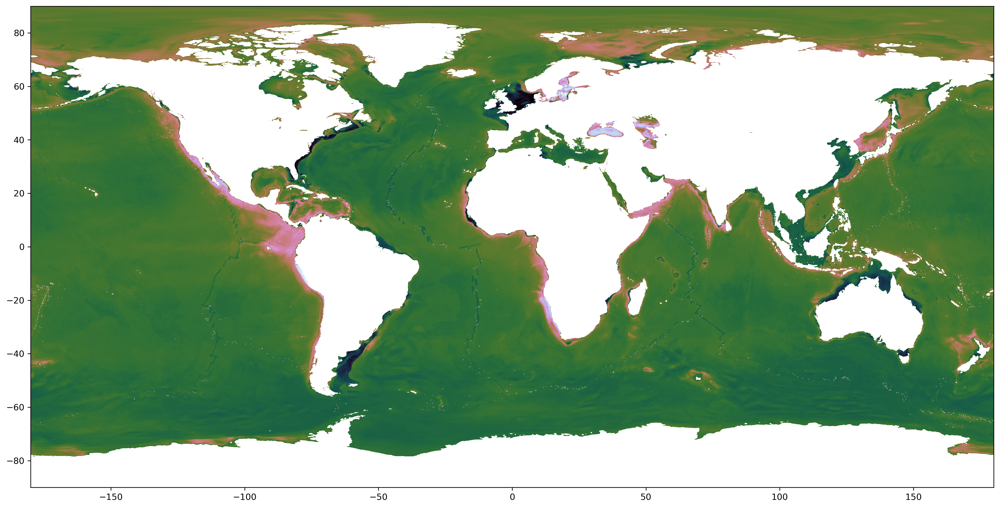

In [15]:

plt.figure(figsize=(20, 10), dpi=300)
plt.imshow(np.mean(prediction_dist_overlapped, axis = 0),norm=LogNorm(vmin=1e-1, vmax=15), cmap="cubehelix", extent=[-180, 180, -90, 90])

In [16]:
import numpy as np
from scipy.stats import norm
from scipy.stats import entropy
from concurrent.futures import ProcessPoolExecutor

def compute_kl_divergence(chunk):
    kl_divergence_chunk = np.empty_like(chunk[:, 0, :])

    for i in range(chunk.shape[1]):
        for j in range(chunk.shape[2]):
            mean = np.mean(chunk[:, i, j], axis=0)
            std = np.std(chunk[:, i, j], axis=0)

            data_original_std = chunk[:, i, j]
            data_new_std = np.random.normal(mean, 0.1, 100)

            pdf_original_std = norm.pdf(data_original_std, mean, std)
            pdf_new_std = norm.pdf(data_new_std, mean, 0.05)

            kl_divergence_chunk[i, j] = entropy(pdf_original_std, pdf_new_std)

    return kl_divergence_chunk

def main():
    prediction_dist_overlapped_shape = prediction_dist_overlapped.shape
    num_chunks = 360
    chunk_size = prediction_dist_overlapped_shape[1] // num_chunks
    chunks_list = []

    for i in range(num_chunks):
        start_index = i * chunk_size
        end_index = (i + 1) * chunk_size
        chunk = prediction_dist_overlapped[:, start_index:end_index, :]
        chunks_list.append(chunk)

    chunks = np.array(chunks_list)

    with ProcessPoolExecutor() as executor:
        futures = [executor.submit(compute_kl_divergence, chunk) for chunk in chunks]

        kl_divergence_result = np.empty_like(prediction_dist_overlapped[:, :, :])

        for idx, future in enumerate(futures):
            start_index = idx * chunk_size
            end_index = (idx + 1) * chunk_size
            kl_divergence_result[:, start_index:end_index, :] = future.result()
            print(f"Completed {idx + 1} out of {num_chunks} chunks.")

if __name__ == "__main__":
    main()

ValueError: could not broadcast input array from shape (100,4320) into shape (100,6,4320)

In [9]:
chunks_test= chunks[0:5, :, :,:]

In [10]:
chunks.shape

(360, 100, 6, 4320)

In [17]:
# -*- coding: utf-8 -*-
"""
@author: wasy
"""

#STEP 1: IMPORT LIBRARIES ----------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import tqdm
from scipy import stats
from scipy.optimize import curve_fit
from scipy import asarray as ar,exp
import time
from scipy.stats import gaussian_kde

In [18]:
chunk.shape

(100, 6, 4320)

In [19]:
# Define the Gaussian function using scipy.stats.norm.pdf
from scipy.stats import norm
#close all opened figure
plt.close("all")
num = 0
start_time = time.time()
def curve_fit_chunk(prediction_dist_overlapped_chunk):
        nan_matrix = np.empty((3, 3))
        nan_matrix.fill(np.nan)
        # Initialize lists to store optimized parameters and covariance matrices for each point
        param_opt_all = np.empty([2, prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
        #cov_matrix_all = np.empty([3, 3, prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
        #tolerance_all = np.empty([ prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
        #failed_fits = []
        #failed_fits_num = 0



        # Given covariance matrix shape
        covariance_matrix_shape = (3, 3)

        # Create a NaN matrix of the same shape
        nan_matrix = np.full(covariance_matrix_shape, np.nan)
        def fit_gaussian_kde(i, j):
            x_data = prediction_dist_overlapped_chunk[:, i, j]

            if np.isnan(x_data).any():
                param_opt_all[:, i, j] = np.array([np.nan, np.nan])
                #cov_matrix_all[:, :, i, j] = nan_matrix
                return
            #print(x_data)
            kde = gaussian_kde(x_data)
            
            # Evaluate KDE on a fine grid
            x_grid = np.linspace(min(data), max(data), 100)
            y_kde = kde(x_grid)
            mean_kde = np.sum(x_grid * y_kde) / np.sum(y_kde)
            std_dev_kde = np.sqrt(np.sum((x_grid - mean_kde)**2 * y_kde) / np.sum(y_kde))

            
            # Extract amplitude, mean, and variance from Gaussian KDE
            #amplitude = np.max(kde.pdf(x_data))
            mean = np.mean(x_data)
            variance = np.var(x_data)

            param_opt_all[:, i, j] = np.array([ mean_kde, std_dev_kde])





        for i in range(prediction_dist_overlapped_chunk.shape[1]):
            print(i)
            for j in range(prediction_dist_overlapped_chunk.shape[2]):
                fit_gaussian_kde(i, j)
        end_time = time.time()
        elapsed_time = end_time - start_time
        print(f"Elapsed time: {elapsed_time} seconds")
        return param_opt_all

param_opt = []

for k in range(chunks.shape[0]):
    print(f"Chunk: {k}")
    param_opt_all= curve_fit_chunk(chunks[k, :, :, :])
    param_opt.append(param_opt_all)

"""
for i in range(prediction_dist_overlapped.shape[1]):
    if i>0:
        break
    for j in range(prediction_dist_overlapped.shape[2]):
        if j>5:
            break
        x_data = prediction_dist_overlapped[:, i, j]

        if np.isnan(x_data).any():
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            continue

        # Calculate mean and standard deviation directly from data
        mean = np.mean(x_data)
        sigma = np.std(x_data)

        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_data, np.ones_like(x_data), p0=[max(x_data), mean, sigma], maxfev=5000
            )

            # Append the results to the lists
            param_opt_all[:, i, j] = param_optimised
            cov_matrix_all[:, :, i, j] = param_covariance_matrix

        except Exception as e:
            print(f"Failed fit at ({i}, {j}) - Number: {failed_fits_num}")
            # Handle the case where fitting fails
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            failed_fits.append((i, j, str(e)))
"""
"""
from multiprocessing import Pool

def process_point(args):
    i, j, x_data = args
    try:
        hist, bin_edges = np.histogram(x_data)
        hist = hist / sum(hist)

        n = len(hist)
        x_hist = np.zeros((n), dtype=float)
        for ii in range(n):
            x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

        y_hist = hist
        mean = sum(x_hist * y_hist) / sum(y_hist)
        sigma = sum(y_hist * (x_hist - mean)) / sum(y_hist)

        # Gaussian least-square fitting process
        param_optimised, param_covariance_matrix = curve_fit(
            gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000
        )

        return param_optimised, param_covariance_matrix
    except Exception as e:
        print("heyy!!")
        return np.array([np.nan, np.nan, np.nan]), np.full(covariance_matrix_shape, np.nan)
        #failed_fits.append((i, j))
# Prepare a list of arguments for each point
point_args = [(i, j, prediction_dist_overlapped[:, i, j])
              for i in range(prediction_dist_overlapped.shape[1])
              for j in range(prediction_dist_overlapped.shape[2])]

# Create a Pool with the number of processes you want
with Pool() as pool:
    # Use map to apply the process_point function to each set of arguments in parallel
    results = pool.map(process_point, point_args)

# Extract the results
param_opt_list, cov_matrix_list = zip(*results)
        


"""

"""

import numpy as np
from scipy.optimize import curve_fit
from multiprocessing import Pool

def fit_gaussian_parallel(args):
    i, j, prediction_dist_overlapped, param_opt_all, cov_matrix_all, nan_matrix, failed_fits, gaus = args
    x_data = prediction_dist_overlapped[:, i, j]
    if np.isnan(x_data).any():
        param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
        cov_matrix_all[:, :, i, j] = nan_matrix
        return

    hist, bin_edges = np.histogram(x_data, bins=100)
    hist = hist / sum(hist)
    n = len(hist)
    x_hist = np.zeros((n), dtype=float)
    for ii in range(n):
        x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2
    y_hist = hist
    mean = sum(x_hist * y_hist) / sum(y_hist)
    sigma = sum(y_hist * (x_hist - mean) ** 2) / sum(y_hist)
    tolerance = 1e-10
    max_iterations = 10
    iteration = 0

    while iteration < max_iterations:
        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000, ftol=tolerance
            )
            break
        except Exception:
            tolerance *= 10
            iteration += 1

    if iteration == max_iterations:
        param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
        cov_matrix_all[:, :, i, j] = nan_matrix
        failed_fits.append((i, j, "Fit failed"))
    else:
        param_opt_all[:, i, j] = param_optimised
        cov_matrix_all[:, :, i, j] = param_covariance_matrix


def gaus(x, a, x0, sigma):
    return a * np.exp(-(x - x0) ** 2 / (2 * sigma ** 2))

# Create a multiprocessing pool
num_processes = 64  # Adjust as needed
with Pool(processes=num_processes) as pool:
    args_list = [(i, j, prediction_dist_overlapped, param_opt_all, cov_matrix_all, nan_matrix, failed_fits, gaus)
                 for i in range(min(2160, prediction_dist_overlapped.shape[1]))
                 for j in range(min(4320, prediction_dist_overlapped.shape[2]))]
    pool.map(fit_gaussian_parallel, args_list)
    # Use tqdm to display the progress
    for _ in tqdm.tqdm(pool.imap_unordered(fit_gaussian_parallel, args_list), total=len(args_list)):
        pass
"""

Chunk: 0
0
1
2
3
4
5
Elapsed time: 11.175546884536743 seconds
Chunk: 1
0
1
2
3
4
5
Elapsed time: 22.479650020599365 seconds
Chunk: 2
0
1
2
3
4
5
Elapsed time: 34.00451040267944 seconds
Chunk: 3
0
1
2
3
4
5
Elapsed time: 45.02896070480347 seconds
Chunk: 4
0
1
2
3
4
5
Elapsed time: 55.94101691246033 seconds
Chunk: 5
0
1
2
3
4
5
Elapsed time: 66.79003763198853 seconds
Chunk: 6
0
1
2
3
4
5
Elapsed time: 77.72298908233643 seconds
Chunk: 7
0
1
2
3
4
5


KeyboardInterrupt: 

In [21]:
import concurrent.futures
import time

def fit_gaussian_kde(x_data):
    kde = gaussian_kde(x_data)
    x_grid = np.linspace(min(data), max(data), 100)
    y_kde = kde(x_grid)
    mean_kde = np.sum(x_grid * y_kde) / np.sum(y_kde)
    std_dev_kde = np.sqrt(np.sum((x_grid - mean_kde)**2 * y_kde) / np.sum(y_kde))
    return mean_kde, std_dev_kde

def curve_fit_chunk(chunk):
    param_opt_all = np.empty([2, chunk.shape[1], chunk.shape[2]])
    for i in range(chunk.shape[1]):
        print(i)
        for j in range(chunk.shape[2]):
            x_data = chunk[:, i, j]
            if np.isnan(x_data).any():
                param_opt_all[:, i, j] = np.array([np.nan, np.nan])
            else:
                mean_kde, std_dev_kde = fit_gaussian_kde(x_data)
                param_opt_all[:, i, j] = np.array([mean_kde, std_dev_kde])
    return param_opt_all

param_opt = []
start_time = time.time()
with concurrent.futures.ProcessPoolExecutor() as executor:
    results = list(executor.map(curve_fit_chunk, chunks))

# Extract the results from the list
for result in results:
    param_opt.append(result)
end_time = time.time()
elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} seconds")

0
0
0
0
00
0

0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
0
00

0
0
0
0
0
0
0
0
0
0
0
000

0

00

0
0
0
0
0
0
00

00

0
0
00

0
1
11

1
1
1
1
11

11

11

1
1
1
11

2
1
2
111


1
1
1
22
2
1

21

1
2
2
1
2
212


2
3
2
1
2
3
1
1
2
1
12

3
1
1
11
1

31
21
1


11

11

1
3
2
3
32

111


1
4
2
1
32

2
1
31

33

2341



2
1
1
43
111



134


13

3
44
5
1

4
3
2
4
5
2
3
355


4
4
4
4
02
33

2

4
3
5
54

4
5
2
052


43

2
43

02

0
2
2
25

2
52

5
0
22

20
4

2
54
2
2
25


2
22

30
2

2
0
252


2
5
4
5
4
2
5
4
3
1
0
0
3
0
2
4
1
10

0
24

2
12

32

0
52

5
21

3
1
02

20

02

1
1
5
3
52

4
3
3
35

1
1
1
2
3
4
3
3
1
1
3
3
23

1
5
2
3
2
33

0
0
35

33
3

3
2
3
41

30
1

1
2
3
2
2
32

50
4

0
3
2
2
3
2
4
3
2
4
2
53

31

0
32
1

3
3
4
40

43

12

3
2
3
33

3
33

4
1
3
4315



43
3

3
0
4
4
4
4
3
3
43

4
3
4
3
45

34

434


4
52

21

4
34

44
4
2

044
3


4
4154



44

2
4
4
24

5
4
1
5
5
5
0
4
4
4
4
3
3
5
2
55

54

5344



505


5
55

515


55
5

4
2
3
5
5
5
5
5
50

4
54

3
45

0
24

5
5
0
4
55

15



In [104]:
len(param_opt)

93

In [97]:
param_opt_all


array([[[1.11837271e-310, 5.72607143e-316, 0.00000000e+000, ...,
         1.11832239e-310, 1.11832239e-310, 1.11832239e-310],
        [1.11832239e-310, 1.11832239e-310, 1.11832239e-310, ...,
         1.11819946e-310, 1.11819946e-310, 1.11819946e-310],
        [1.11819946e-310, 1.11819946e-310, 1.11819946e-310, ...,
         1.11832417e-310, 1.11832417e-310, 1.11832417e-310],
        [1.11832417e-310, 1.11832417e-310, 1.11832417e-310, ...,
         1.11820117e-310, 1.11820117e-310, 1.11820117e-310],
        [1.11820117e-310, 1.11820117e-310, 1.11820117e-310, ...,
         1.11830471e-310, 1.11830471e-310, 1.11809905e-310],
        [1.11809905e-310, 1.11809905e-310, 1.11809905e-310, ...,
         1.11832765e-310, 1.11832765e-310, 1.11832765e-310]],

       [[1.11832586e-310, 1.11832586e-310, 1.11832586e-310, ...,
         0.00000000e+000, 0.00000000e+000, 0.00000000e+000],
        [0.00000000e+000, 0.00000000e+000, 0.00000000e+000, ...,
         9.42183187e-321, 1.11832056e-310, 1.118320

In [137]:
x_data  =np.array([0.77101166,0.57599662,0.88017252,0.87319419,0.79999329,0.89310149
,0.71596027,0.85414201,0.85075379,0.70355014,0.91639515,0.85396168
,0.75970738,0.88155053,0.77783073,1.31913921,0.73073384,0.82429089
,0.87414367,0.94126956,0.52190157,0.85724026,0.78082619,0.73238773
,0.83128394,0.75154662,0.78611948,0.76185225,0.5693197,0.95837949
,0.71771695,0.85392534,1.01599022,0.67580623,0.96233442,0.93112448
,0.68652716,0.86117764,0.8093308,0.73016317,0.91359501,0.74556233
,0.78731408,1.11716573,0.75362698,0.49688815,0.75921295,0.72561648
,0.83810251,0.91467964,0.68545899,0.79843283,0.71780162,0.58580774
,1.0825782,0.74266046,0.79849982,0.82792831,0.78348251,0.80599049
,0.65094664,0.78649202,0.73294757,0.70729061,0.89953039,0.79890436
,0.74075912,0.81374624,0.66444897,0.82944625,0.56668417,0.83849208
,0.75639003,0.818517,0.77959122,0.93636576,0.9000249,0.80244932
,0.64780284,0.63695732,0.78930711,0.72834278,0.81862847,0.58724794
,0.73673617,0.78045022,0.74274956,0.94096256,0.75865739,1.11436813
,0.73907192,0.89830046,0.81221911,0.88199609,0.66971043,0.81587027
,0.66237416,0.69714262,0.63099595,0.82817828])

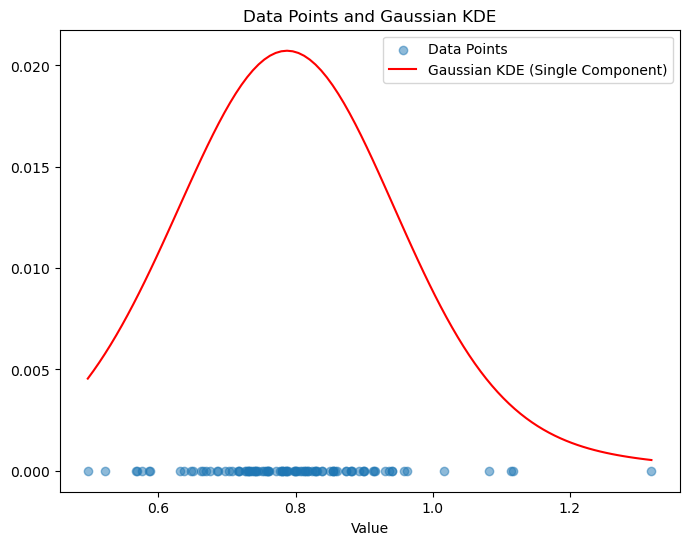

In [138]:
data = x_data
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

# Generate a random distribution
np.random.seed(42)
#data = np.random.normal(loc=0, scale=1, size=1000)

# Fit Gaussian KDE with a small bandwidth to get a single component
kde = gaussian_kde(data, bw_method=1)

# Evaluate KDE on a fine grid
x_grid = np.linspace(min(data), max(data), 100)
y_kde = kde(x_grid)

# Plot data points and KDE curve
plt.figure(figsize=(8, 6))
plt.scatter(data, np.zeros_like(data), alpha=0.5, label='Data Points')
plt.plot(x_grid, y_kde/sum(y_kde), color='red', label='Gaussian KDE (Single Component)')
plt.title('Data Points and Gaussian KDE')
plt.xlabel('Value')
#plt.yticks([])  # Hide y-axis
plt.legend()
plt.show()


In [139]:
# Calculate the mean of the KDE
mean_kde = np.sum(x_grid * y_kde) / np.sum(y_kde)
print("Mean of the KDE:", mean_kde)

Mean of the KDE: 0.8057978590487723


In [140]:
np.mean(x_data)

0.7941335351999999

In [141]:
# Calculate the standard deviation of the KDE
std_dev_kde = np.sqrt(np.sum((x_grid - mean_kde)**2 * y_kde) / np.sum(y_kde))

print("Standard Deviation of the KDE:", std_dev_kde)



Standard Deviation of the KDE: 0.1570561055820381


In [142]:
hist, bin_edges = np.histogram(x_data, bins=500) # bins affect the curve that we obtain, but it mainly affects the height of the curve
hist = hist / sum(hist)

n = len(hist)
x_hist = np.zeros((n), dtype=float)
for ii in range(n):
    x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

y_hist = hist
mean = np.mean(x_data)#sum(x_hist * y_hist) / sum(y_hist)
sigma = np.std(x_data)#sum(y_hist * (x_hist - mean) ** 2) / sum(y_hist)
#if sigma<0:
#    print(sigma)
sigma_squared = sigma **2
tolerance = 1e-10  # Initial tolerance value
max_iterations = 10  # Maximum number of iterations
iteration = 0

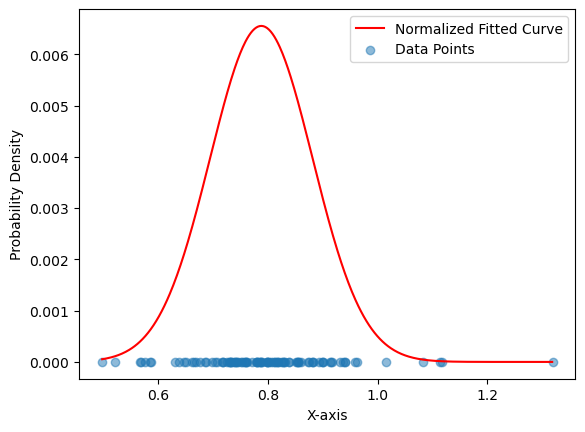

0.7879544342186272
0.09339409010299578


In [144]:
# Define the Gaussian function using scipy.stats.norm.pdf
def gaus(x, a, x0, sigma):
    #if sigma <0:
    #    print(sigma)
    return a * norm.pdf(x, loc=x0, scale=sigma)
# Gaussian least-square fitting process
param_optimised, param_covariance_matrix = curve_fit(gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000, ftol=tolerance)

#plt.hist(x_data, bins=100, density=True, alpha=0.5, label='Data Histogram')
plt.plot(x_hist, gaus(x_hist, *param_optimised), 'r-', label='Normalized Fitted Curve')
plt.scatter(x_data, np.zeros_like(x_data), alpha=0.5, label='Data Points')

plt.xlabel('X-axis')
plt.ylabel('Probability Density')
plt.legend()
plt.show()
print(param_optimised[1])
print(param_optimised[2])

In [77]:
def plot_fit(i, j):
    x_data = prediction_dist_overlapped_chunk[:, i, j]
    
    if np.isnan(x_data).any():
        # Handle NaN values as needed
        return 

    hist, bin_edges = np.histogram(x_data, bins=500)
    hist = hist / sum(hist)

    n = len(hist)
    x_hist = np.zeros((n), dtype=float)
    for ii in range(n):
        x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

    y_hist = hist

    # Plot histogram
    plt.figure(figsize=(8, 6))
    plt.hist(x_data, bins=500, density=True, alpha=0.7, label='Histogram')

    # Plot fitted Gaussian curve
    x_curve = np.linspace(min(x_hist), max(x_hist), 100)
    y_curve = gaus(x_curve, *param_opt_all[:, i, j])
    plt.plot(x_curve, y_curve, 'r-', label='Fitted Gaussian')

    plt.title(f'Curve Fit for Point ({i}, {j})')
    plt.xlabel('X-axis label')
    plt.ylabel('Frequency')
    plt.legend()
    plt.show()

# ... (rest of the code)

# After fitting
# Assuming you want to plot for the last dataset
plot_fit(chunks_test.shape[1] - 1, chunks_test.shape[2] - 1)

NameError: name 'prediction_dist_overlapped_chunk' is not defined

In [98]:

x_data = prediction_dist_overlapped_chunk[:, i, j]
# Print fit Gaussian parameters
print("Fit parameters: ")
print("=====================================================")
print("C = ", param_opt[0][0])#, "+-", np.sqrt(cov_matrix[0, 0]))
print("X_mean =", param_opt[0][1])#, "+-", np.sqrt(cov_matrix[1, 1]))
print("sigma = ", param_opt[0][2])#, "+-", np.sqrt(cov_matrix[2, 2]))
print("actual mean = ", np.mean(x_data))
print("\n")

# Plotting the Gaussian curve
fig, ax = plt.subplots()
x_data_sorted = np.sort(x_data)
ax.plot(x_data_sorted, gaus(x_data_sorted, *param_optimised), 'r.:', label='Gaussian fit')

# Normalize the histogram values
weights = np.ones_like(x_data) / len(x_data)
ax.hist(x_data, weights=weights, alpha=0.5, label='Data',bins = 100)

# Setting the label, title, and grid of the plot
ax.set_xlabel("Data: Random variable")
ax.set_ylabel("Probability")
ax.grid(True)
ax.legend()

plt.show()

NameError: name 'prediction_dist_overlapped_chunk' is not defined

In [95]:
import concurrent.futures
import time
from scipy.stats import gaussian_kde
start_time = time.time()

# Define the Gaussian function using scipy.stats.norm.pdf
def gaus(x, a, x0, sigma):
    #if sigma <0:
    #    print(sigma)
    return a * norm.pdf(x, loc=x0, scale=sigma)

def curve_fit_chunk_parallel(prediction_dist_overlapped_chunk):
    nan_matrix = np.empty((3, 3))
    nan_matrix.fill(np.nan)
    # Initialize lists to store optimized parameters and covariance matrices for each point
    param_opt_all = np.empty([2, prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
    #cov_matrix_all = np.empty([3, 3, prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
    #tolerance_all = np.empty([prediction_dist_overlapped_chunk.shape[1], prediction_dist_overlapped_chunk.shape[2]])
    #failed_fits = []
    #failed_fits_num = 0


    def fit_gaussian_kde(i, j):
        x_data = prediction_dist_overlapped_chunk[:, i, j]

        if np.isnan(x_data).any():
            param_opt_all[:, i, j] = np.array([np.nan, np.nan])
            #cov_matrix_all[:, :, i, j] = nan_matrix
            return
        #print(x_data)
        kde = gaussian_kde(x_data, bw_method=1)

        # Evaluate KDE on a fine grid
        x_grid = np.linspace(min(data), max(data), 100)
        y_kde = kde(x_grid)
        mean_kde = np.sum(x_grid * y_kde) / np.sum(y_kde)
        std_dev_kde = np.sqrt(np.sum((x_grid - mean_kde)**2 * y_kde) / np.sum(y_kde))


        # Extract amplitude, mean, and variance from Gaussian KDE
        #amplitude = np.max(kde.pdf(x_data))
        mean = np.mean(x_data)
        variance = np.var(x_data)

        param_opt_all[:, i, j] = np.array([ mean_kde, std_dev_kde])





    for i in range(prediction_dist_overlapped_chunk.shape[1]):
        for j in range(prediction_dist_overlapped_chunk.shape[2]):
            fit_gaussian_kde(i, j)
    """

    for i in range(prediction_dist_overlapped_chunk.shape[1]):
        for j in range(prediction_dist_overlapped_chunk.shape[2]):
            fit_gaussian_serial(i, j)
    """
    return param_opt_all

param_opt_list = []
with concurrent.futures.ProcessPoolExecutor() as executor:
    results = list(executor.map(curve_fit_chunk_parallel, chunks))

# Extract the results from the list
for result in results:
    param_opt_list.append(result)
end_time = time.time()    


elapsed_time = end_time - start_time
print(f"Elapsed time: {elapsed_time} seconds")


Process ForkProcess-432:
Process ForkProcess-411:
Process ForkProcess-441:
Process ForkProcess-433:
Process ForkProcess-424:
Process ForkProcess-422:
Process ForkProcess-400:
Process ForkProcess-391:
Process ForkProcess-398:
Process ForkProcess-407:
Process ForkProcess-443:
Process ForkProcess-438:
Process ForkProcess-435:


KeyboardInterrupt: 

Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
Traceback (most recent call last):
  File "/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  Fil

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def gaussian(x, amplitude, mean, stddev):
    return amplitude * np.exp(-((x - mean) / (2 * stddev))**2)

def custom_kde(data, bins=100, tolerance=1e-10):
    hist, bin_edges = np.histogram(data, bins=bins, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

    def fit_gaussian(x, amplitude, mean, stddev):
        return amplitude * np.exp(-((x - mean) / (2 * stddev))**2)

    params, covariance = curve_fit(fit_gaussian, bin_centers, hist, p0=[1, np.mean(data), np.std(data)], tol=tolerance)

    kde_values = fit_gaussian(bin_centers, *params)

    return bin_centers, kde_values

# Example usage
np.random.seed(42)
data_uniform = np.random.uniform(low=-1, high=1, size=1000)

tolerance = 1e-10

# Calculate custom KDE
x_custom_kde, custom_kde_values = custom_kde(data_uniform, tolerance=tolerance)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(x_custom_kde, custom_kde_values, label=f'Custom KDE (Tolerance={tolerance})')
plt.scatter(data_uniform, np.zeros_like(data_uniform), alpha=0.5, label='Data Points (Uniform Distribution)')
plt.title('Custom KDE and Data Points')
plt.xlabel('Value')
plt.yticks([])  # Hide y-axis
plt.legend()

plt.show()

TypeError: leastsq() got an unexpected keyword argument 'tol'

In [13]:
kde.mean()

AttributeError: 'gaussian_kde' object has no attribute 'mean'

In [66]:
param_opt_list[3][1,:,:]

array([[0.75957407, 0.77828997, 0.77319795, ..., 0.77351324, 0.7612492 ,
        0.75216049],
       [0.74923197, 0.74276194, 0.75102513, ..., 0.7907287 , 0.75978033,
        0.7560025 ],
       [0.7279444 , 0.75498797, 0.75000466, ..., 0.75558484, 0.74526672,
        0.73431758],
       [0.74018937, 0.75751356, 0.72449966, ..., 0.71048979, 0.72781763,
        0.73562475],
       [0.74856923, 0.75535536, 0.74414893, ..., 0.74953573, 0.7329515 ,
        0.72535131],
       [0.73049917, 0.7454283 , 0.76905154, ..., 0.74876233, 0.74603474,
        0.75844749]])

In [41]:
param_opt[0][1,:,:]

array([[0.78795443, 0.78997468, 0.77881508, ..., 0.79234429, 0.79002413,
        0.76718696],
       [0.79005012, 0.77244665, 0.79398742, ..., 0.77082192, 0.7846219 ,
        0.77838469],
       [0.81045233, 0.76821283, 0.77448223, ..., 0.76131271, 0.77909768,
        0.7819916 ],
       [0.80926058, 0.82033018, 0.80449138, ..., 0.77598492, 0.76905786,
        0.79650867],
       [0.80393306, 0.79870789, 0.77834706, ..., 0.77665931, 0.76698697,
        0.76566828],
       [0.76939178, 0.78374603, 0.77120618, ..., 0.94921747, 0.96785692,
        0.94185766]])

In [105]:
param_opt_list = np.concatenate(param_opt, axis=1)

In [106]:
param_opt_list.shape

(2, 558, 4320)

In [69]:
np.save("param_opt_list", param_opt_list)

In [70]:
tolerance_list = np.concatenate(tolerance_list, axis=0)

In [71]:
tolerance_list.shape

(2160, 4320)

In [72]:
np.save("tolerance_list", tolerance_list)

In [73]:
cov_matrix_list[0].shape

(3, 3, 6, 4320)

In [74]:
cov_matrix_list = np.concatenate(cov_matrix_list, axis=2)

In [75]:
cov_matrix_list.shape

(3, 3, 2160, 4320)

In [76]:
np.save("cov_matrix_list", cov_matrix_list)

In [30]:
len(failed_fits_num_list)

360

In [8]:
param_opt_list = np.load("param_opt_list.npy")
tolerance_list = np.load("tolerance_list.npy")
cov_matrix_list = np.load("cov_matrix_list.npy")


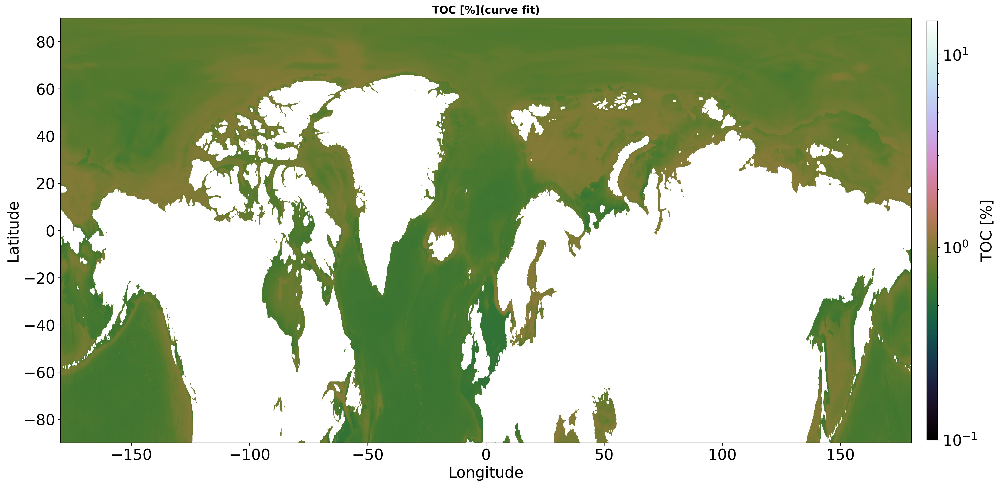

In [107]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi=300)
plt.imshow(param_opt_list[0,:,:],norm=LogNorm(vmin=1e-1, vmax=15), cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC [%]', fontsize=20)
plt.title("TOC [%](curve fit)", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi=300)

plt.show()

In [78]:
np.nanmin(param_opt_list[2,:,:])

0.009569101014814676

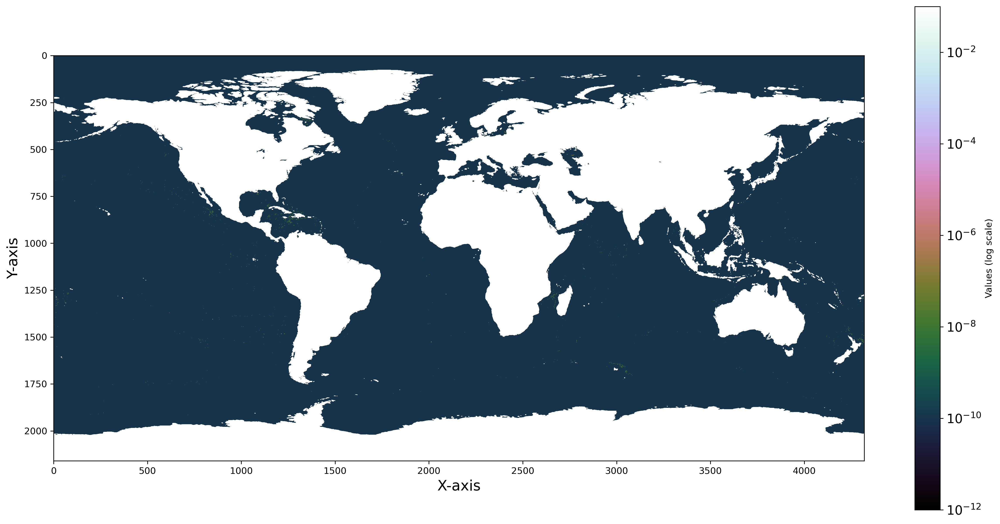

In [79]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
tolerance_list[land_map] = np.nan
# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(tolerance_list, norm=LogNorm(vmin = 1e-12, vmax = 1e-1), cmap='cubehelix')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)

# Show the plot
plt.show()

In [112]:
import numpy as np
from scipy.stats import norm

# Assuming param_optimised[1] is the mean and param_optimised[2] is the standard deviation
mean = param_opt_list[0, :557, :]
#C = param_opt_list[0, :, :]
sigma = param_opt_list[1,:557,:]
#std_dev = np.sqrt(sigma)
probability_at_mean =np.empty([557, 4320])
"""
for i in range(probability_at_mean.shape[0]):#probability_at_mean.shape[0]
    print(i)
    for j in range(probability_at_mean.shape[1]):#probability_at_mean.shape[1]
        # Calculate the probability density at the mean value
        #print(norm(mean, sigma).pdf(mean[]))
        probability_at_mean[i,j] = norm(mean[i,j], sigma[i,j]).pdf(np.mean(prediction_dist_overlapped[:, i, j]))
"""
probability_at_mean = norm(mean, sigma).pdf(np.mean(prediction_dist_overlapped[:, :557, :], axis=0))

In [81]:
probability_at_mean.shape

(2160, 4320)

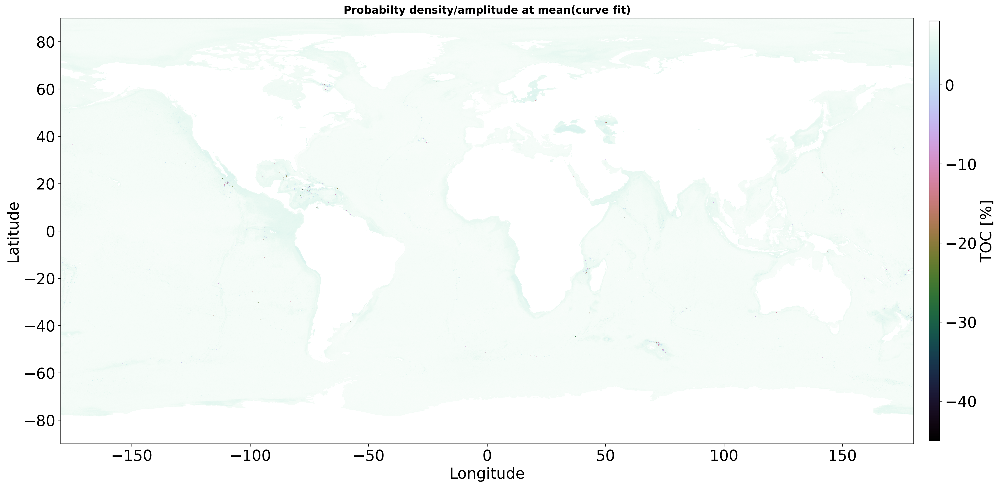

In [82]:
"""
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration

plt.figure(figsize=(20, 10), dpi=300)
plt.imshow(-np.log(param_opt_list[0,:,:]) ,cmap="cubehelix", extent=[-180, 180, -90, 90])#,norm=LogNorm(vmin=1e-2, vmax=1)
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('TOC [%]', fontsize=20)
plt.title("Probabilty density/amplitude at mean(curve fit)", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi=300)

plt.show()
"""

/tmp/ipykernel_1080598/1222328349.py:8: RuntimeWarning: divide by zero encountered in log
  plt.imshow(-np.log(probability_at_mean), vmin = -4, vmax = 200, cmap="cubehelix", extent=[-180, 180, -90, 90])


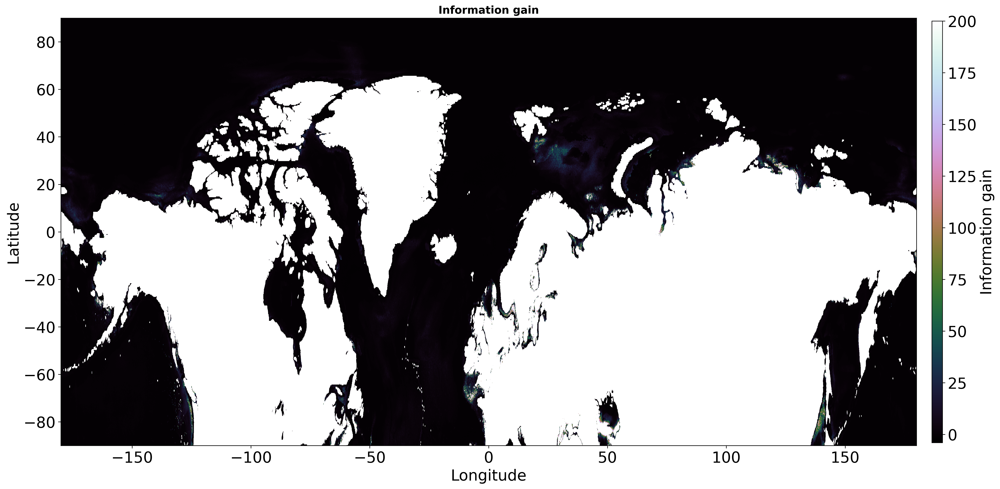

In [117]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Generate some example data for demonstration. the proabbiltiy density can be greater than 1?

plt.figure(figsize=(20, 10), dpi=300)
plt.imshow(-np.log(probability_at_mean), vmin = -4, vmax = 200, cmap="cubehelix", extent=[-180, 180, -90, 90])
#plt.title(filename)
# Commenting out the title
# plt.title("Mass Accumulation Rate Using K-Nearest Neighbours", fontsize=14, fontweight='bold')

# Add text at the bottom of the plot
#additional_text = "k = 8  |  Sediment Budget: $6.4 \\times 10^4$ Mt/yr"
#plt.text(0.5, -0.08, additional_text, transform=plt.gca().transAxes, fontsize=10, ha='center', color='gray')
# Adjust the size of the color bar using the shrink parameter
cbar = plt.colorbar(label='TOC [%]', aspect=40, pad=0.015, shrink=0.8)
cbar.ax.tick_params(labelsize=20)  # Increase font size for color bar ticks and labels
cbar.set_label('Information gain', fontsize=20)
plt.title("Information gain", fontsize=14, fontweight='bold')


plt.xticks(fontsize=20)  # Increase font size for x-axis ticks
plt.yticks(fontsize=20)
plt.xlabel("Longitude", fontsize=20)
plt.ylabel("Latitude", fontsize=20)
plt.tight_layout()

# Save the plot
#plt.savefig('mass_accumulation_plot.png', dpi=300)

plt.show()

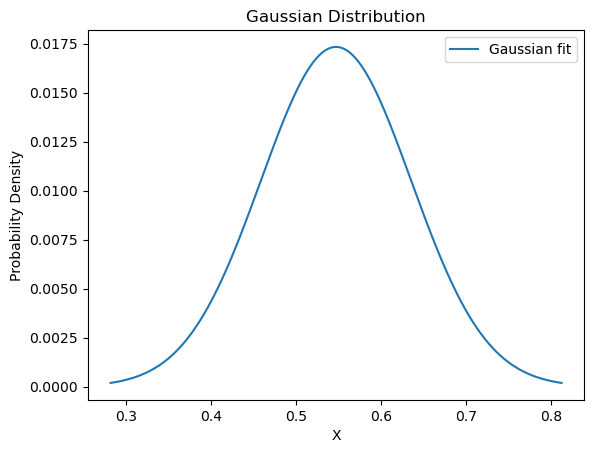

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import exp

# Define the Gaussian function
def gaus(X, C, X_mean, sigma):
    return C * np.exp(-(X - X_mean)**2 / (2 * sigma**2))

# Parameters
C =  0.01733634326479251
X_mean = 0.546938694261047
sigma =  0.08831113713633054

# Generate x values
x_values = np.linspace(X_mean - 3 * sigma, X_mean + 3 * sigma, 1000)

# Calculate y values using the Gaussian function
y_values = gaus(x_values, C, X_mean, sigma)

# Plot the Gaussian curve
plt.plot(x_values, y_values, label='Gaussian fit')
plt.title('Gaussian Distribution')
plt.xlabel('X')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

In [5]:
i

25

In [ ]:
import multiprocessing
import itertools
# Close all opened figures
plt.close("all")

# Initialize lists to store optimized parameters and covariance matrices for each point
param_opt_all = np.zeros([3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
cov_matrix_all = np.zeros([3, 3, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])
failed_fits = []

# Given covariance matrix shape
covariance_matrix_shape = (3, 3)

# Create a NaN matrix of the same shape
nan_matrix = np.full(covariance_matrix_shape, np.nan)

# Calculating the Gaussian PDF values given Gaussian parameters and random variable X
def gaus(X, C, X_mean, sigma):
    return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))

# Function to fit a chunk of points
def fit_chunk(chunk):
    for indices in chunk:
        i, j = indices
        x_data = prediction_dist_overlapped[:, i, j]

        if np.isnan(x_data).any():
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            continue

        hist, bin_edges = np.histogram(x_data)
        hist = hist / sum(hist)

        n = len(hist)
        x_hist = np.zeros((n), dtype=float)
        for ii in range(n):
            x_hist[ii] = (bin_edges[ii + 1] + bin_edges[ii]) / 2

        y_hist = hist
        mean = sum(x_hist * y_hist) / sum(y_hist)
        sigma = sum(y_hist * (x_hist - mean) ** 2) / sum(y_hist)
        try:
            # Gaussian least-square fitting process
            param_optimised, param_covariance_matrix = curve_fit(
                gaus, x_hist, y_hist, p0=[max(y_hist), mean, sigma], maxfev=5000
            )

            # Append the results to the lists
            param_opt_all[:, i, j] = param_optimised
            cov_matrix_all[:, :, i, j] = param_covariance_matrix

        except Exception as e:
            print(f"Failed fit at ({i}, {j})")
            # Handle the case where fitting fails
            param_opt_all[:, i, j] = np.array([np.nan, np.nan, np.nan])
            cov_matrix_all[:, :, i, j] = nan_matrix
            failed_fits.append((i, j, str(e)))

# Generate all pairs of indices
index_pairs = list(itertools.product(range(prediction_dist_overlapped.shape[1]), range(prediction_dist_overlapped.shape[2])))

# Split the index pairs into chunks
num_processes = 64  # Adjust as needed
chunk_size = len(index_pairs) // num_processes
chunks = [index_pairs[i:i + chunk_size] for i in range(0, len(index_pairs), chunk_size)]

# Create a multiprocessing pool
with multiprocessing.Pool(processes=num_processes) as pool:
    # Map the function over all chunks
    pool.map(fit_chunk, chunks)

# Continue with the rest of your code after the parallel fitting process

/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipyke

Failed fit at (405, 132)
Failed fit at (337, 2173)


/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))
/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))


Failed fit at (472, 3890)


/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))


Failed fit at (438, 3881)
Failed fit at (405, 133)
Failed fit at (304, 98)


... (71 outputs left out)

/tmp/ipykernel_2065244/284285142.py:18: DeprecationWarning: scipy.exp is deprecated and will be removed in SciPy 2.0.0, use numpy.exp instead
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))



Failed fit at (1316, 1707)
Failed fit at (1113, 3466)

Failed fit at (1923, 4120)
Failed fit at (1957, 4195)
Failed fit at (1046, 1565)Failed fit at (338, 1043)


Failed fit at (405, 1109)
Failed fit at (810, 252)Failed fit at (1991, 1492)

Failed fit at (304, 1266)Failed fit at (1316, 1708)

Failed fit at (506, 2076)
Failed fit at (1586, 1411)Failed fit at (540, 1118)

Failed fit at (607, 2797)Failed fit at (1957, 4196)Failed fit at (1046, 1566)Failed fit at (1248, 3658)Failed fit at (1113, 3467)Failed fit at (1282, 2688)




Failed fit at (405, 1110)Failed fit at (1012, 3072)

Failed fit at (304, 1267)
Failed fit at (1991, 1493)
Failed fit at (810, 253)
Failed fit at (978, 3948)Failed fit at (540, 1366)


Failed fit at (1586, 1418)Failed fit at (1957, 4197)Failed fit at (1046, 1567)


Failed fit at (1113, 3468)
Failed fit at (473, 446)
Failed fit at (304, 1269)Failed fit at (810, 254)
Failed fit at (1721, 1250)Failed fit at (1248, 3661)

Failed fit at (506, 2080)Failed fit at (1991,

/tmp/ipykernel_2065244/284285142.py:18: RuntimeWarning: overflow encountered in scalar power
  return C * exp(-(X - X_mean) ** 2 / (2 * sigma ** 2))



Failed fit at (931, 2846)

Failed fit at (1901, 2551)Failed fit at (595, 1277)

Failed fit at (1998, 4193)Failed fit at (1729, 3042)

Failed fit at (1864, 3311)Failed fit at (457, 2208)Failed fit at (860, 1218)


Failed fit at (761, 1154)
Failed fit at (555, 2765)
Failed fit at (622, 2791)
Failed fit at (530, 2785)
Failed fit at (356, 2135)Failed fit at (53, 1862)Failed fit at (293, 1213)

Failed fit at (1933, 1228)
Failed fit at (1901, 2553)Failed fit at (1832, 1433)


Failed fit at (250, 2728)
Failed fit at (1964, 1437)Failed fit at (1092, 3453)Failed fit at (331, 1266)

Failed fit at (595, 1279)
Failed fit at (1998, 4194)Failed fit at (385, 2133)
Failed fit at (1729, 3045)


Failed fit at (457, 2210)Failed fit at (1864, 3313)

Failed fit at (761, 1156)Failed fit at (622, 2792)

Failed fit at (860, 1264)
Failed fit at (293, 1215)Failed fit at (1933, 1229)
Failed fit at (356, 2136)Failed fit at (1901, 2556)
Failed fit at (1832, 1441)

Failed fit at (331, 1267)Failed fit at (1092, 345

In [21]:

np.save("param_opt_all", param_opt_all)
np.save("cov_matrix_all", cov_matrix_all)


In [41]:
param_opt_all.shape

(3, 2160, 4320)

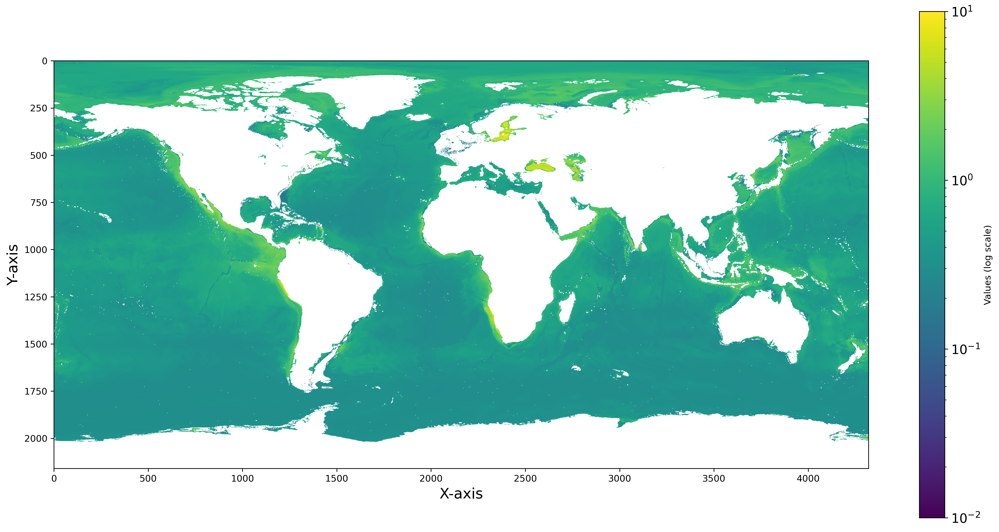

In [22]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(param_opt_all[1,:,:], norm=LogNorm(vmin = 1e-2, vmax = 1e1), cmap='viridis')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)

# Show the plot
plt.show()

In [20]:
param_covariance_matrix

array([[ 2.82491331e-04,  1.01779381e-05, -1.40430205e-04],
       [ 1.01779381e-05,  1.64092971e-04, -1.84864821e-05],
       [-1.40430205e-04, -1.84864821e-05,  1.93772911e-04]])

In [67]:
array_params = np.array(param_opt_list)

In [73]:
pred_plot = array_params[:, 1].reshape([2160, 4320])

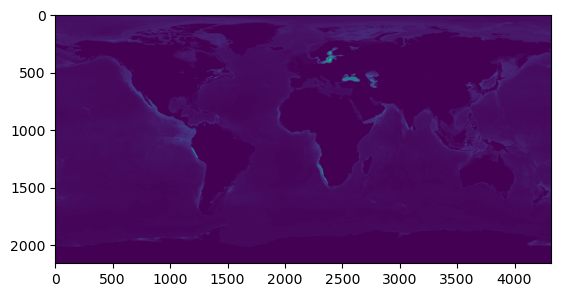

In [74]:
plt.imshow(pred_plot)

In [78]:
nan_count = np.sum(np.isnan(pred_plot))

In [79]:
nan_count

0

In [59]:
param_covariance_matrix

array([[ 6.24618640e-04,  7.69801859e-06, -1.11193605e-04],
       [ 7.69801859e-06,  4.87248771e-05, -4.86608084e-06],
       [-1.11193605e-04, -4.86608084e-06,  5.56605389e-05]])

In [57]:
j

2573

In [53]:
param_optimised

array([0.16281686, 0.87228466, 0.15794354])

In [43]:
param_optimised



array([0.18187037, 0.49663386, 0.12396819])

In [44]:
np.mean(x_data)

0.5015274787872661

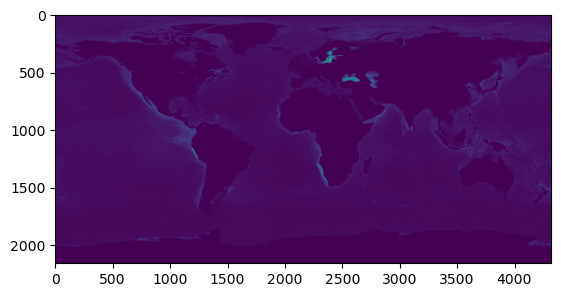

In [30]:
plt.imshow(pm_overlapped)

In [34]:
from scipy.stats import norm
from scipy.optimize import curve_fit
import numpy as np
from multiprocessing import Pool, Manager

# Define the Gaussian density function
def gaussian_density(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu)**2 / (2 * sigma**2))


def fit_gaussian_point(point, failed_fits_count, failed_fit_details):
    i, j, data_point = point

    # Check if data_point contains NaN values, and skip fitting if it does
    if np.isnan(data_point).any():
        #print("nan!")
        return None
    
    x_values = np.arange(len(data_point))
    #print(x_values)
    try:
        # Fit a Gaussian distribution to the data with an improved initial guess
        #print(data_point)
        mu_init = np.mean(data_point)
        sigma_init = np.std(data_point)
        params, covariance = curve_fit(gaussian_density, data_point, np.ones_like(data_point), p0=[mu_init, sigma_init])
        #print(mu_init)
        #print(params)
        return i, j, params
    except Exception as e:
        #print(f"Fit failed for point ({i}, {j}): {str(e)}")
        failed_fits_count.value += 1
        failed_fit_details.append((i, j, str(e)))
        # Write details of failed fits to a file
        with open("failed_fits.txt", "a") as file:
            file.write(f"Failed fit at point ({i}, {j})\n")
        return None

def fit_gaussian_to_predictions(predictions_sum):
    # Assume predictions_sum is your array of shape (100, 6, 4320)
    num_samples, num_points_x, num_points_y = predictions_sum.shape

    # Fitting parameters for each point
    fit_params_gaussian = np.zeros((num_points_x, num_points_y, 2))  # Assuming Gaussian has two parameters (mu, sigma)

    # Count the number of points where the fitting process fails
    manager = Manager()
    failed_fits_count = manager.Value('i', 0)

    # List to store details of failed fits
    failed_fit_details = []

    # Create a list of tuples for each point and its data
    data_points = [(i, j, predictions_sum[:, i, j]) for i in range(num_points_x) for j in range(num_points_y)]

    # Use multiprocessing Pool to parallelize the fitting process
    with Pool() as pool:
        results = pool.starmap(fit_gaussian_point, [(point, failed_fits_count, failed_fit_details) for point in data_points])

    # Process the results
    for result in results:
        if result is not None:
            i, j, params = result
            fit_params_gaussian[i, j] = params # if it is a failed it, the parameters are zeros

    return fit_params_gaussian, failed_fits_count.value, failed_fit_details

In [35]:
failed_fits_all = []
i = 0
fit_params, failed_fits, failed_fit_details = fit_gaussian_to_predictions(prediction_dist_overlapped)
failed_fits_all.append(failed_fits)
print(i)

0


In [9]:
fit_params.shape

(2160, 4320, 2)

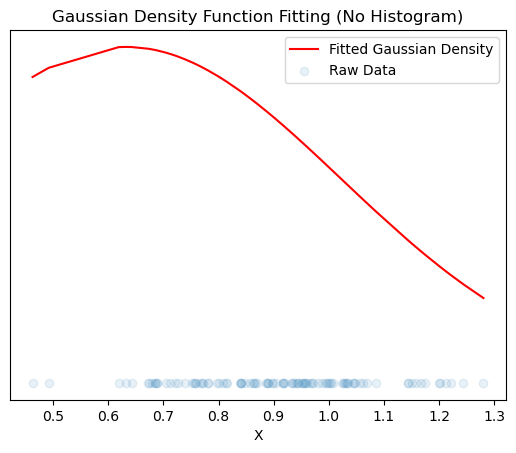

In [41]:
data_sorted = np.sort(np.array([0.8992284,0.64216938,0.72083345,0.61897456,0.95636716,1.03103221
,0.86562204,0.91620787,0.89651731,1.22087333,1.15084729,1.05662739
,1.00728028,0.88969563,0.67865741,0.7553292,0.88895589,0.88783405
,0.94396591,0.92119506,0.95072876,1.04710319,0.68896078,0.86210692
,0.80161336,0.99769682,1.06250473,0.9811982,1.20125157,1.16668452
,1.04486901,0.76980455,1.14434303,0.98800745,0.95748919,0.46262657
,0.91700443,0.83856155,0.88638888,0.67279094,0.68450257,1.24396308
,0.86992251,0.67467948,0.71273175,0.68551212,0.68835024,0.94410795
,0.75988937,0.75196944,0.91762554,1.03477068,0.83984773,0.93297423
,0.97185578,0.95581373,1.06872661,0.63153915,0.84088853,0.78082185
,0.72608487,0.96681017,0.9691959,0.90442117,0.93694084,1.15730095
,0.77216115,1.03387009,0.93346171,0.96019669,0.49184222,0.78163356
,0.95062926,0.81595537,1.20023368,1.08629296,1.00286424,0.76632207
,0.86427943,0.75754356,1.02414923,0.94081433,1.28054607,0.81361242
,0.99281039,0.80737341,0.84139903,0.73863604,1.14321148,1.02785847
,1.17532813,0.8481121,1.02728824,0.79722016,1.00377424,1.21307479
,0.99616684,0.85772861,0.70401102,1.04449312]))
# Plot the raw data and the fitted Gaussian density function
plt.plot(data_sorted, gaussian_density(data_sorted, fit_params[0][0][0], fit_params[0][0][1]), color='red', label='Fitted Gaussian Density')
plt.scatter(data_sorted, np.zeros_like(data_sorted), alpha=0.1, label='Raw Data')
plt.title('Gaussian Density Function Fitting (No Histogram)')
plt.xlabel('X')
plt.yticks([])  # Hide y-axis ticks for better visualization
plt.legend()
plt.show()

# Print the optimized 

In [42]:
from scipy.stats import shapiro

# Example: data_sorted is your sorted dataset, and fit_params contains the parameters of your fitted Gaussian distribution
#data_sorted = np.sort(data)
mu, sigma = fit_params[0][0]

# Compute the Gaussian density for the sorted data
gaussian_density_values = gaussian_density(data_sorted, mu, sigma)

# Shapiro-Wilk test
stat, p_value = shapiro(gaussian_density_values)
print(f'Statistic: {stat}, p-value: {p_value}')

# Check if p-value is greater than your significance level (e.g., 0.05)
if p_value > 0.05:
    print('The distribution appears to be Gaussian.')
else:
    print('The distribution does not appear to be Gaussian.')

Statistic: 0.9348333477973938, p-value: 9.460484579904005e-05
The distribution does not appear to be Gaussian.


In [43]:
gaussian_density(data_sorted, mu, sigma)

array([0.92902063, 0.95690725, 1.019826  , 1.02038933, 1.02004317,
       1.01484471, 1.01432125, 1.01314219, 1.01122224, 1.01086812,
       1.00983718, 1.00960859, 1.00321622, 0.99885322, 0.99437353,
       0.99125319, 0.98311623, 0.97344573, 0.97084587, 0.96909702,
       0.96721394, 0.96189121, 0.95891356, 0.95686074, 0.94905788,
       0.94830598, 0.93320248, 0.92872238, 0.92270443, 0.91600573,
       0.91344265, 0.88743928, 0.88589323, 0.88463709, 0.88401934,
       0.87579692, 0.86370758, 0.85808683, 0.85527161, 0.85352324,
       0.84787982, 0.82569008, 0.8237008 , 0.82215214, 0.82112885,
       0.81161523, 0.8077967 , 0.80042536, 0.78342932, 0.78226817,
       0.78136171, 0.77613465, 0.75868373, 0.75795522, 0.75274213,
       0.74691072, 0.74214572, 0.74193054, 0.73201436, 0.73186252,
       0.72408186, 0.72323266, 0.72150961, 0.71734439, 0.70712842,
       0.70342955, 0.69929775, 0.6847256 , 0.6740538 , 0.66650497,
       0.66122061, 0.65880963, 0.65065784, 0.64922102, 0.64368

/tmp/ipykernel_1693803/1393154981.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(gaussian_density(data_sorted, mu, sigma))
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/gxfs_home/cau/sunms498/.conda/envs/pytorch/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating i

<Axes: ylabel='Density'>

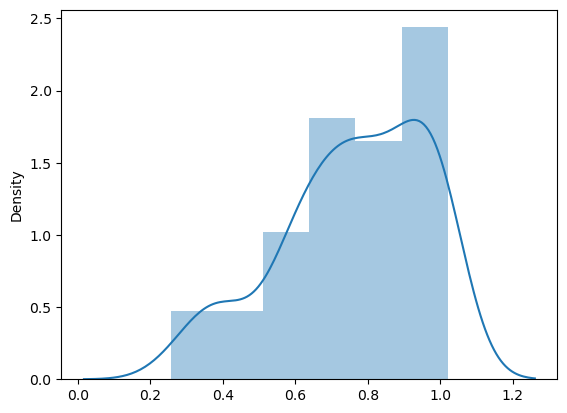

In [47]:
import seaborn as sns
sns.distplot(gaussian_density(data_sorted, mu, sigma))

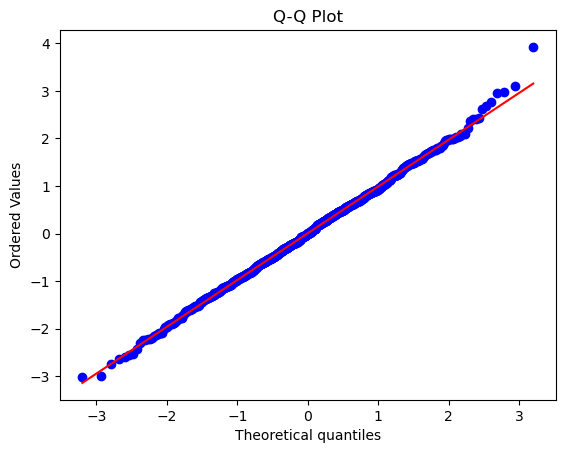

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import probplot

# Example: data is your dataset
data = np.random.normal(0, 1, 1000)

# Create a Q-Q plot
probplot(data, plot=plt)
plt.title('Q-Q Plot')
plt.show()


In [135]:
fit_params[0][0][0]

0.9073608867420614

In [136]:
np.mean(data_sorted)

0.9073608862

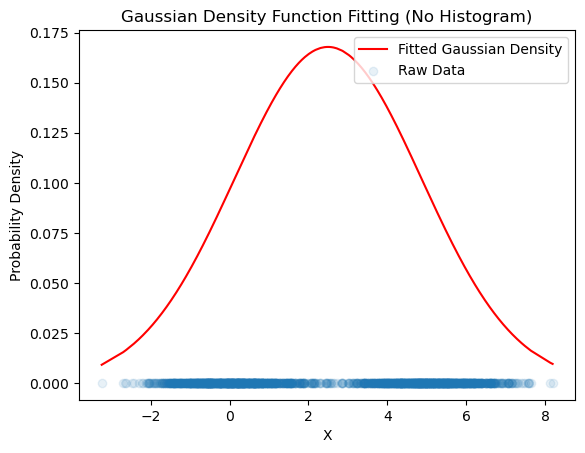

Optimized mean (mu): 2.4989480886524635
Optimized standard deviation (sigma): 2.3759555773424843


In [36]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Define the Gaussian density function
def gaussian_density(x, mu, sigma):
    return 1 / (sigma * np.sqrt(2 * np.pi)) * np.exp(-(x - mu)**2 / (2 * sigma**2))

# Generate synthetic data with noise
np.random.seed(42)  # for reproducibility
data = np.concatenate([np.random.normal(0, 1, 1000), np.random.normal(5, 1, 1000)])
# Sort the data for better visualization
data_sorted = np.sort(data)

# Calculate the probability density for each data point
pdf_values = np.zeros_like(data_sorted)
for i, x in enumerate(data_sorted):
    pdf_values[i] = np.sum(data_sorted < x) / len(data_sorted)

# Initial guesses for the parameters
mu_init = np.mean(data)
sigma_init = np.std(data)

# Fit the data to the Gaussian density function using curve_fit
params, covariance = curve_fit(gaussian_density,  data_sorted, np.ones_like(data_sorted), p0=[mu_init, sigma_init])

# Extract optimized parameters
mu_optimized, sigma_optimized = params

# Plot the raw data and the fitted Gaussian density function
plt.plot(data_sorted, gaussian_density(data_sorted, mu_optimized, sigma_optimized), color='red', label='Fitted Gaussian Density')
plt.scatter(data_sorted,np.zeros_like(data), alpha=0.1, label='Raw Data')
plt.title('Gaussian Density Function Fitting (No Histogram)')
plt.xlabel('X')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

# Print the optimized mean and standard deviation
print(f"Optimized mean (mu): {mu_optimized}")
print(f"Optimized standard deviation (sigma): {sigma_optimized}")

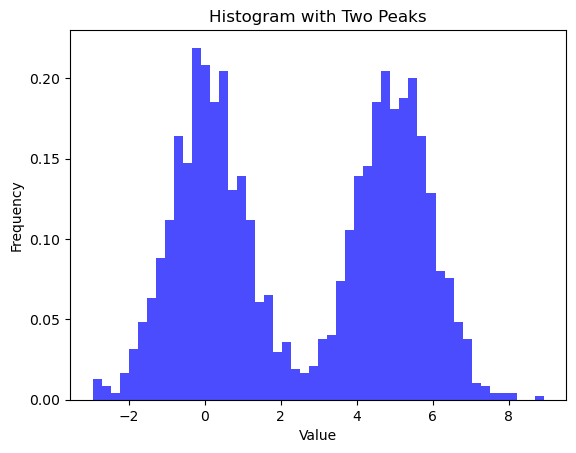

In [29]:
import numpy as np
import matplotlib.pyplot as plt

# Generate data with two peaks
data = np.concatenate([np.random.normal(0, 1, 1000), np.random.normal(5, 1, 1000)])

# Plot the histogram
plt.hist(data, bins=50, color='blue', alpha=0.7, density=True)
plt.title('Histogram with Two Peaks')
plt.xlabel('Value')
plt.ylabel('Frequency')

plt.show()

In [20]:
np.mean(data)

3.028998083733488

In [44]:
np.arange(10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [37]:
fit_params

array([[[ 8.71597187e+03,  2.63632949e+03,  1.97035253e+03],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 1.92805786e+02,  6.48744770e+01,  1.04731194e+02],
        [ 2.44076302e+02,  7.27925166e+01,  1.34498688e+02],
        [ 3.65514996e+02,  4.13000297e+00,  2.00352616e+02]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 2.38286059e+04,  8.09354516e+03,  9.57273912e+03],
        [ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],

       [[ 2.56573443e+02,  6.38264839e+01,  1.44269151e+02],
        [ 1.35222829e+02,  5.97330626e+01,  8.44360787e+01],
        [ 5.56751256e+02,  4.16129711e+01,  4.22016405e+02],
        [ 4.49558155e+02,  4.23324853e+01,  1.94134379e+02],
        [ 4.16681674e+02,  3.92401863e+01,  1.72657091e+02]],

       [[ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
        [ 3.062931

In [13]:
failed_fits

0

In [9]:
failed_fits/(2160*4320)

0.004116833847736625

In [10]:
fit_params.shape

(2160, 4320, 2)

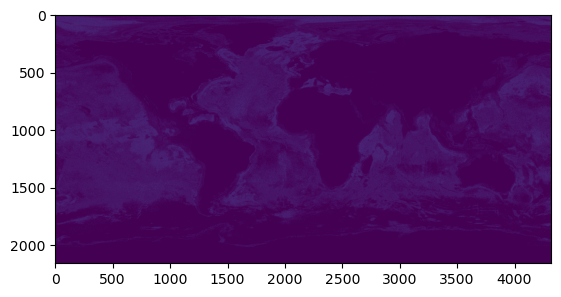

In [11]:
plt.imshow(fit_params[:,:,1])

In [5]:
np.save("fit_params", fit_params)

In [12]:
fit_params = np.load("fit_params.npy")

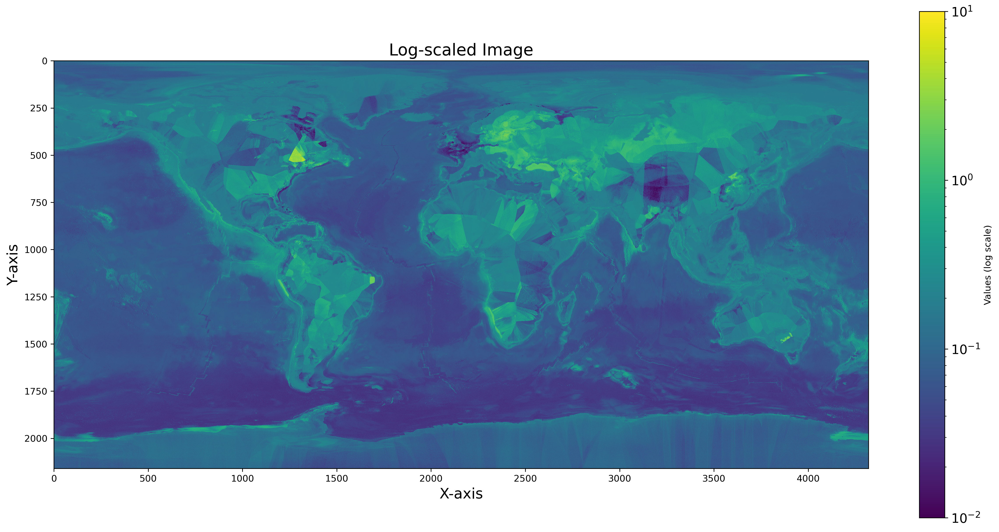

In [17]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(np.std(prediction_dist_overlapped, axis = 0), norm=LogNorm(vmin = 1e-2, vmax = 1e1), cmap='viridis')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()

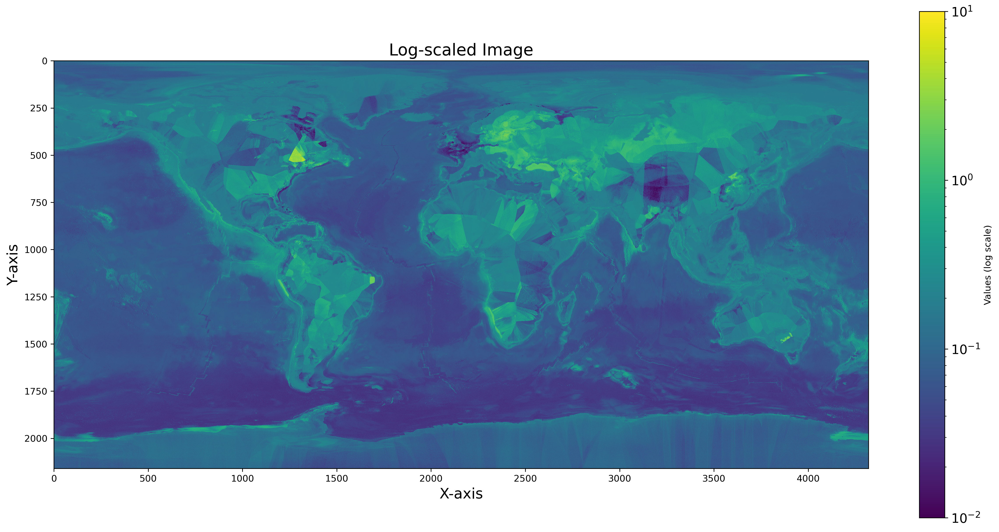

In [16]:
#plt.imshow(pm_overlapped)
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np

# Assuming fit_params is a 3D array
#fit_params = np.random.rand(10, 10, 2)  # Replace this with your actual data

# Plotting
plt.figure(figsize=(20, 10), dpi = 300)
plt.imshow(fit_params[:, :, 1], norm=LogNorm(vmin = 1e-2, vmax = 1e1), cmap='viridis')

# Adding colorbar
cbar = plt.colorbar(label='Values (log scale)')
cbar.ax.tick_params(labelsize=14)

# Adding labels and title
plt.xlabel('X-axis', fontsize=16)
plt.ylabel('Y-axis', fontsize=16)
plt.title('Log-scaled Image', fontsize=18)

# Show the plot
plt.show()